In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_score, recall_score, f1_score

In [8]:
df = pd.read_csv('dataset.csv', index_col=0)
print(df.shape)
df.head(10)

(569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440
6,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368
7,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510
8,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720
9,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750


In [ ]:
df = df.drop('id', axis=1)
df.head(10)

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440
6,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368
7,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510
8,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720
9,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,...,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750


In [10]:

df.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    str    
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  569 non-null

In [13]:

duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


In [15]:
missing_values = df.isna().sum()
if missing_values.any():
    print("Missing values found:")
    print(missing_values[missing_values > 0])
else:
    print("No missing values found.")

No missing values found.


In [26]:
class_counts = df['diagnosis'].value_counts()
print("Class distribution:")
print(class_counts)

percentage = df['diagnosis'].value_counts(normalize=True) * 100
print("\nClass distribution percentage:")
print(percentage)

print(f'Count, Percentage of patients with Benign Tumors: {class_counts["B"]}, {percentage["B"]:.1f}%')
print(f'Count, Percentage of patients with Malignant Tumors: {class_counts["M"]}, {percentage["M"]:.1f}%')

Class distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64

Class distribution percentage:
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64
Count, Percentage of patients with Benign Tumors: 357, 62.7%
Count, Percentage of patients with Malignant Tumors: 212, 37.3%


In [28]:
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()
print(f'Total number of numeric columns: {len(numeric_columns)}')

Total number of numeric columns: 30


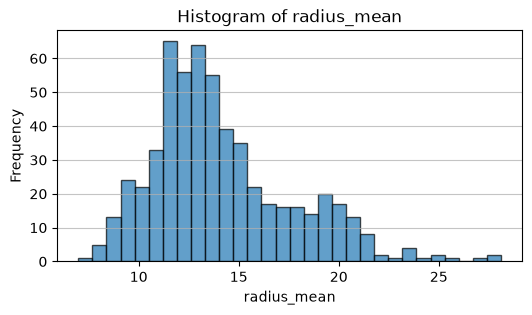

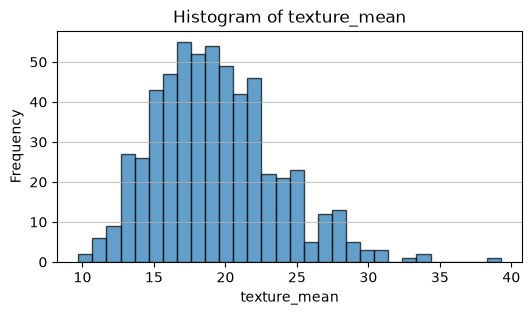

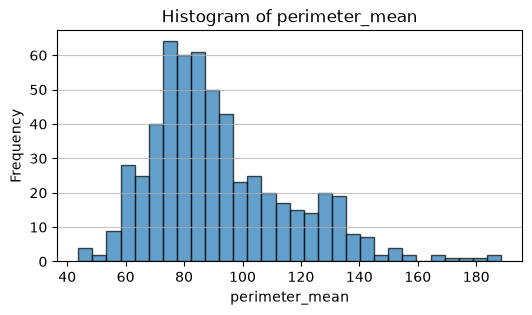

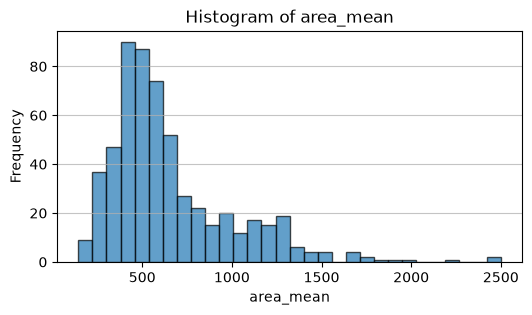

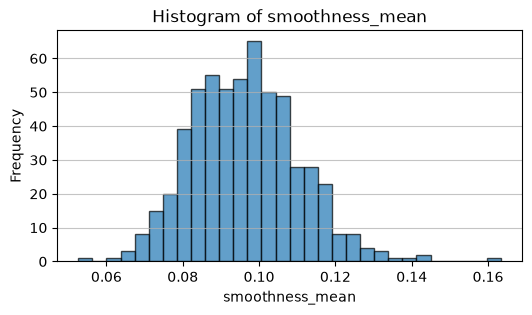

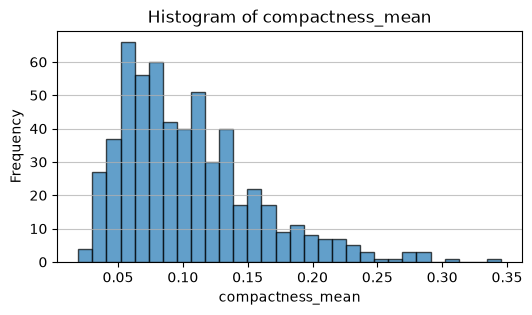

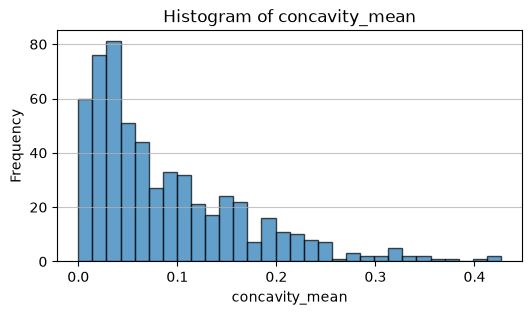

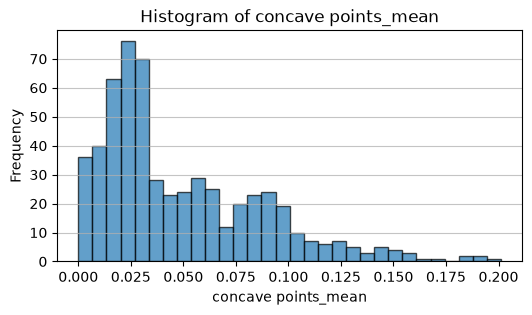

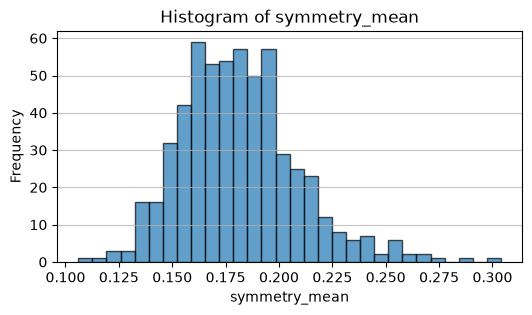

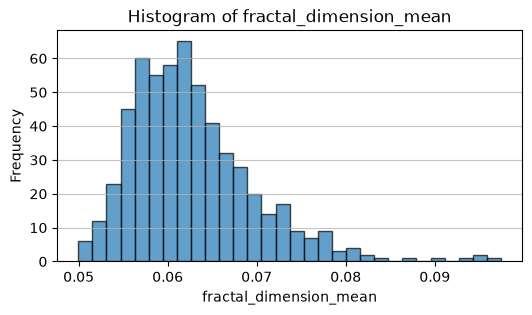

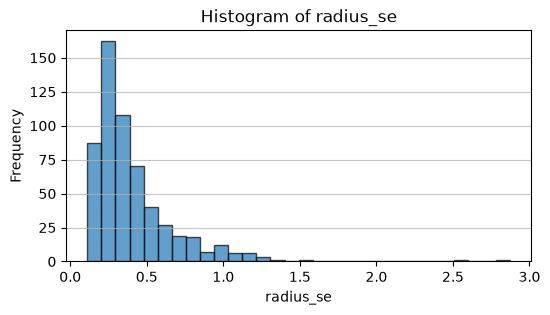

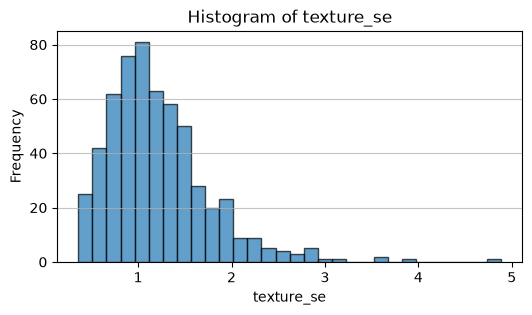

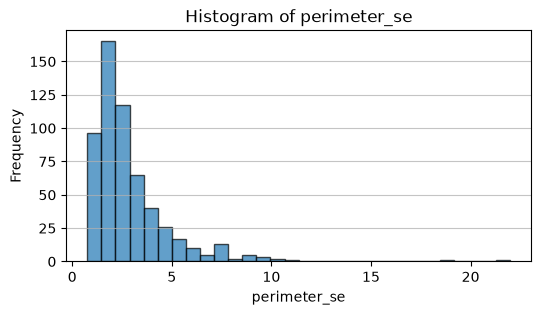

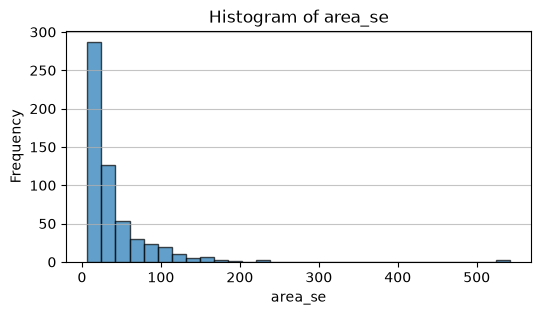

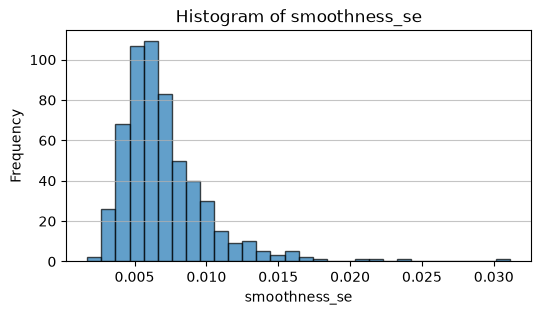

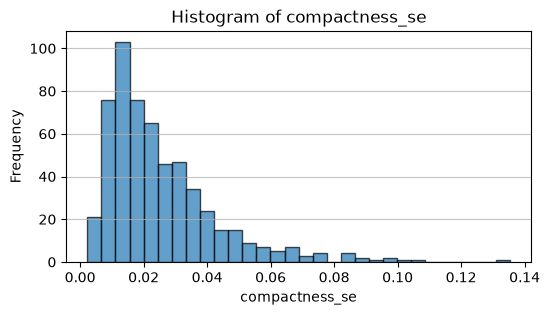

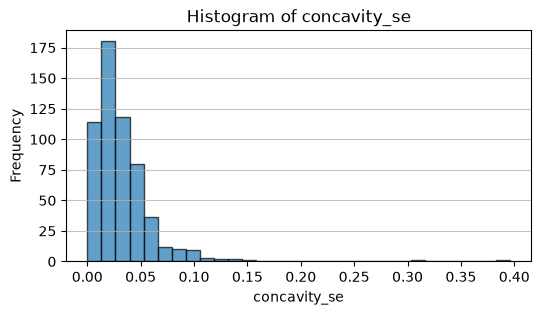

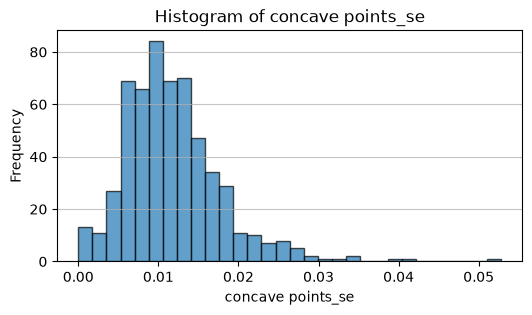

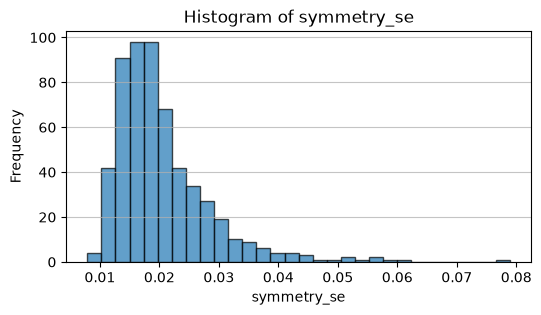

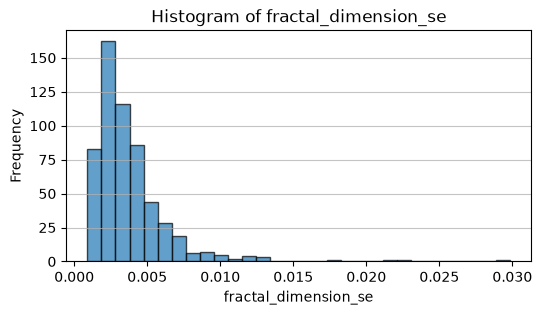

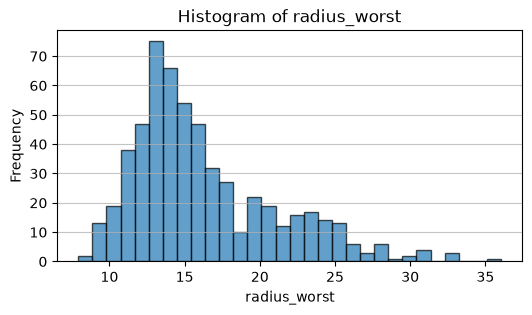

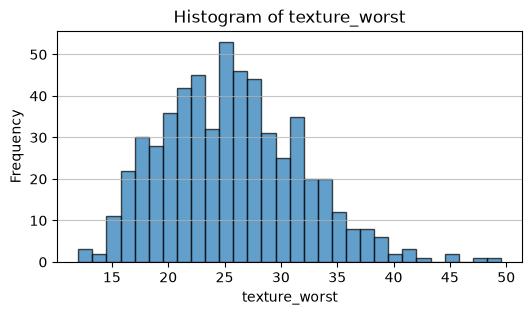

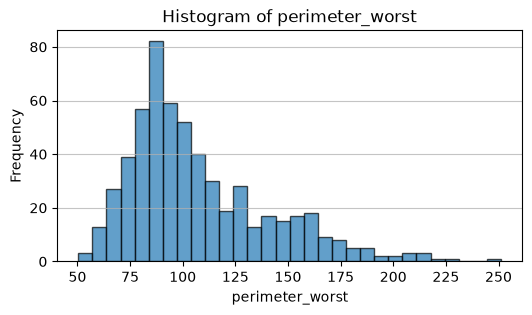

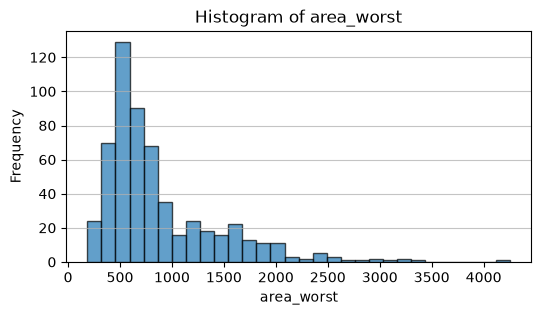

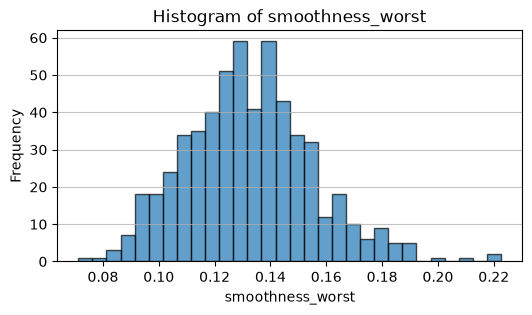

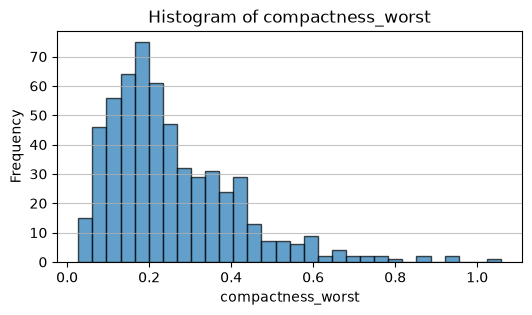

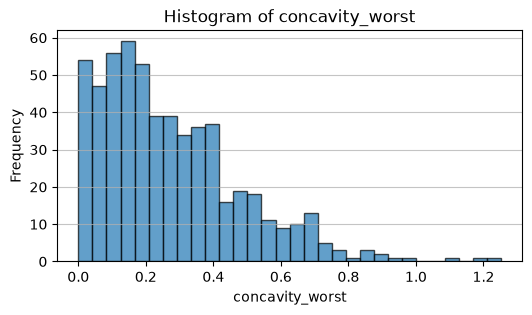

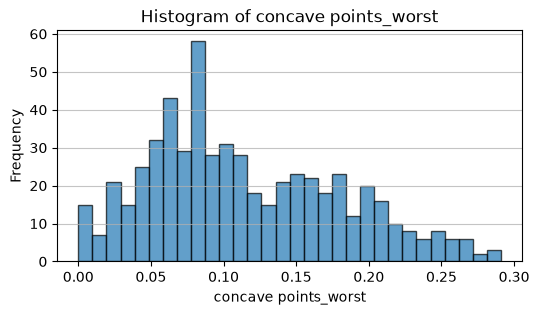

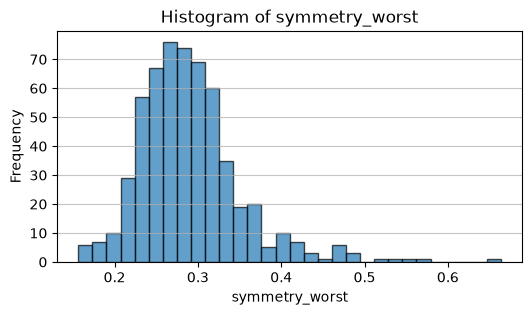

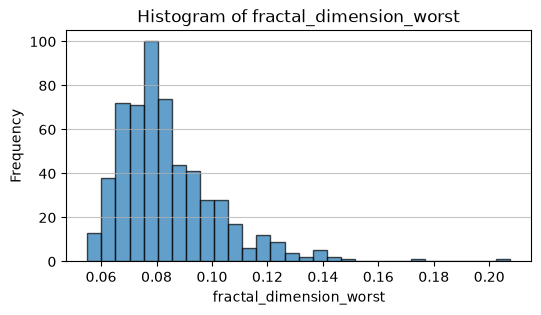

In [84]:
for col in numeric_columns:
    plt.figure(figsize=(6, 3))
    plt.hist(df[col].dropna(), bins=30, edgecolor='k', alpha=0.7)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.show()
    # print(f'Skewness of {col}: {df[col].skew()}')

In [31]:
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()
print(f'Categorical columns: {categorical_columns}')

Categorical columns: ['diagnosis']


/var/folders/qv/pmc9vgc57y15_pg8xyr527s80000gn/T/ipykernel_9486/3458283678.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object']).columns.tolist()


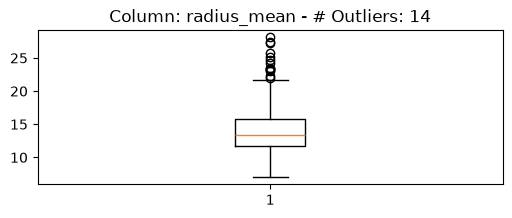

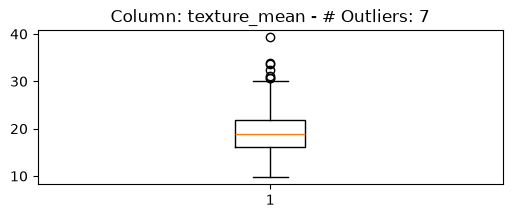

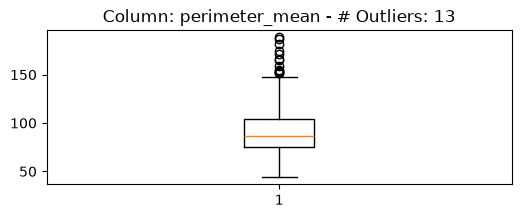

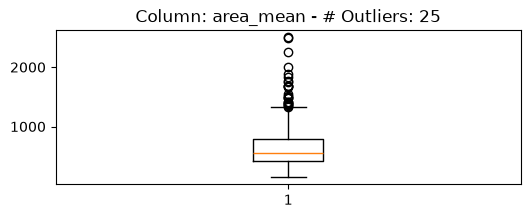

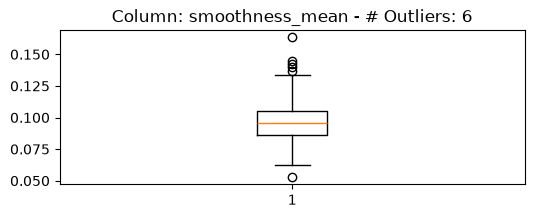

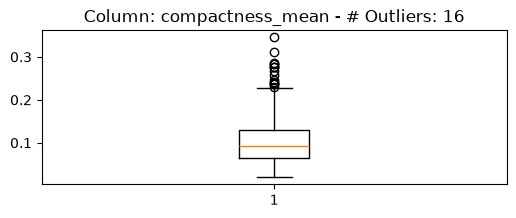

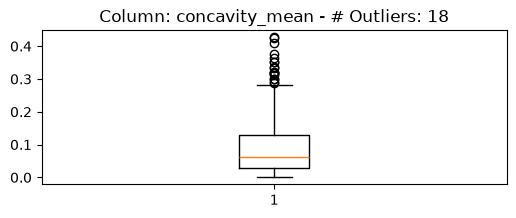

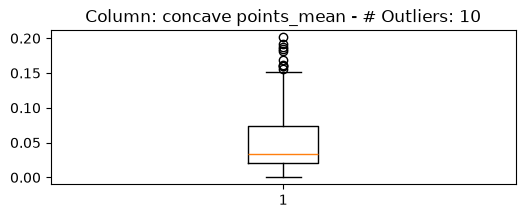

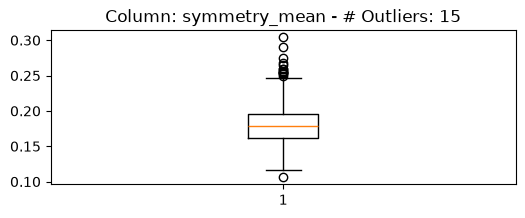

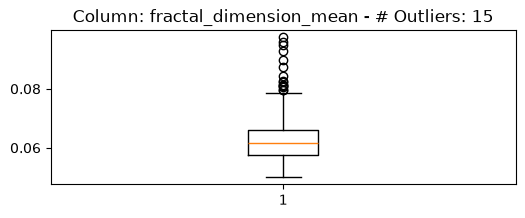

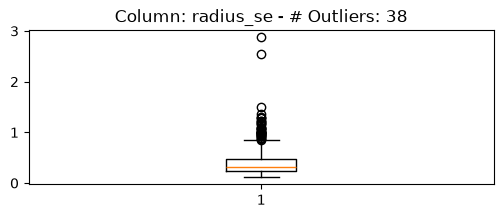

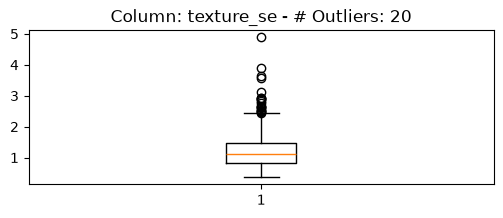

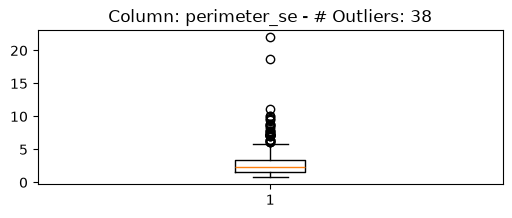

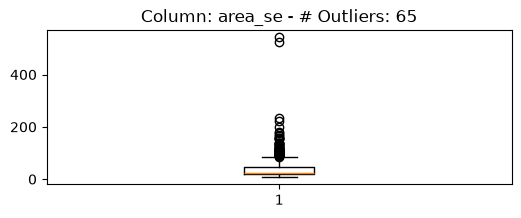

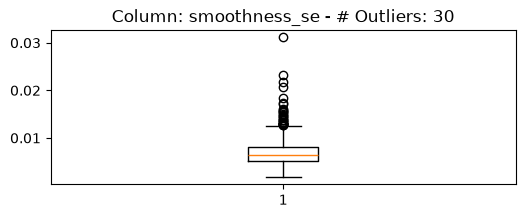

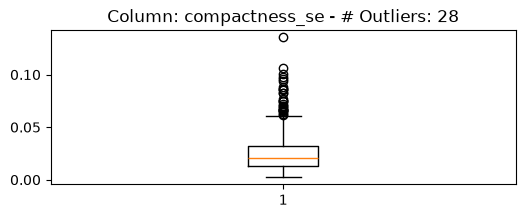

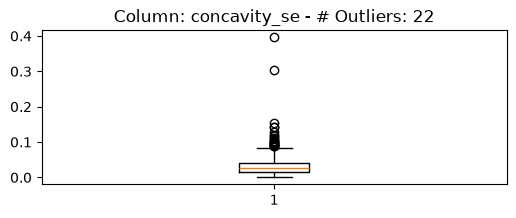

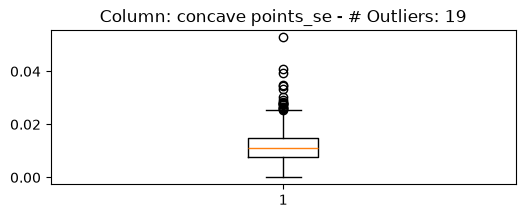

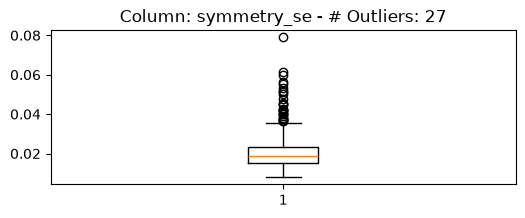

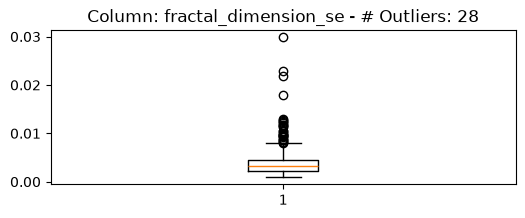

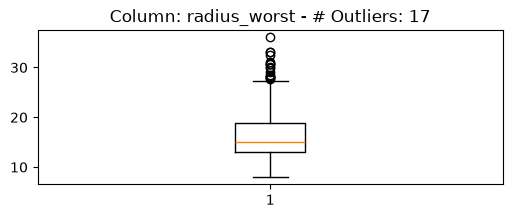

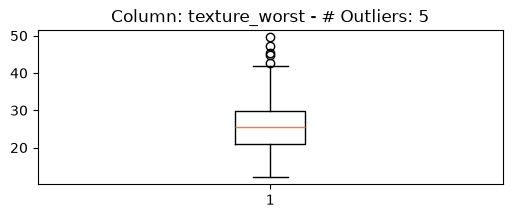

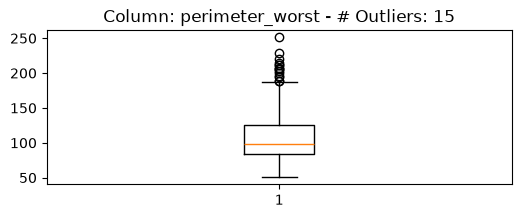

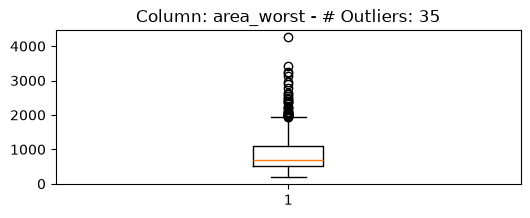

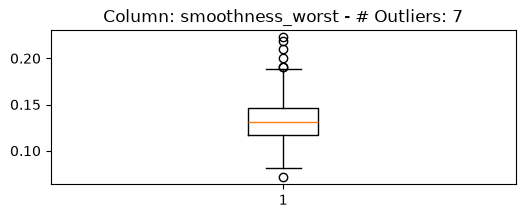

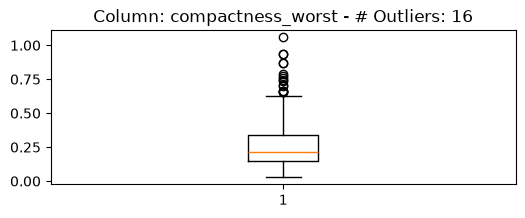

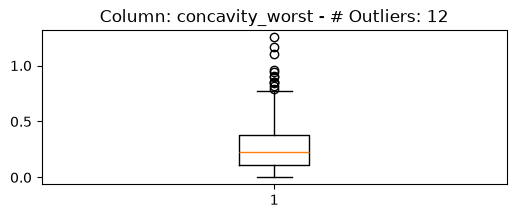

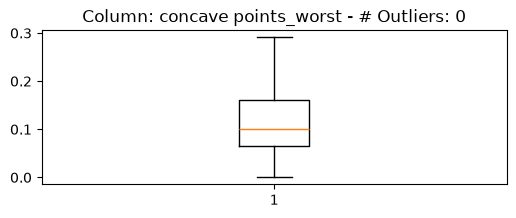

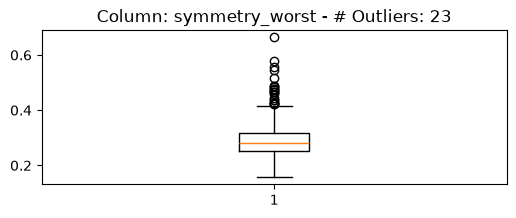

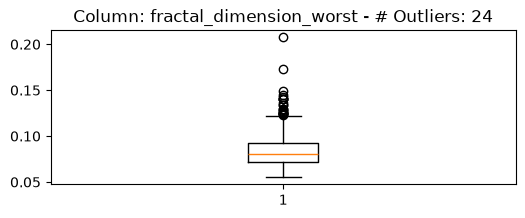

In [36]:
for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outlier_mask = (df[col] < lower_bound) | (df[col] > upper_bound) # Boolean mask: True where the value is an outlier
    number_of_outliers = outlier_mask.sum()

    plt.figure(figsize=(6, 2)) # Create a new figure for each box plot
    plt.boxplot(df[col].dropna()) # Generate a box plot for the current column, dropping missing values
    plt.title(f'Column: {col} - # Outliers: {number_of_outliers}') # Set the title of the box plot including the outlier count (this is the count found BEFORE imputation)
    plt.show()

In [72]:
X = df.drop('diagnosis', axis=1)
y = df['diagnosis'].map({'B': -1, 'M': 1})  # Map 'B' to -1 and 'M' to 1

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# Split data into training and test sets (80% train, 20% test)
# 'random_state' ensures reproducibility, 'stratify=y' maintains the same proportion of target classes in both splits


In [73]:
print(f"Total patients: {len(df)}") # Print the total number of patients in the original dataset
print(f"Training set size: {len(X_train)} ({len(X_train)/len(df)*100:.0f}%)") # Print the size and percentage of the training set
print(f"Test set size: {len(X_test)} ({len(X_test)/len(df)*100:.0f}%)") # Print the size and percentage of the test set

print(
f"  Class split in training: " # Print header for class distribution in training set
    f"{(y_train==-1).sum()/len(X_train):.1%} Benign, "
    f"{(y_train==1).sum()/len(X_train):.1%} Malignent"
)

print(
    f"  Class split in test:     " # Print header for class distribution in test set
    f"{(y_test==-1).sum()/len(X_test):.1%} Benign, "
    f"{(y_test==1).sum()/len(X_test):.1%} Malignant"
)

print("\nstratify=y ensures both splits have the same % of Benign vs Malignant cases") # Explain the purpose of stratify=y

Total patients: 569
Training set size: 455 (80%)
Test set size: 114 (20%)
  Class split in training: 62.6% Benign, 37.4% Malignent
  Class split in test:     63.2% Benign, 36.8% Malignant

stratify=y ensures both splits have the same % of Benign vs Malignant cases


In [74]:
impute_outliers_Flag = True  # Set to True to impute outliers with the column median, False to just visualize/count them as before

for col in numeric_columns: # Iterate through each numeric column

  Q1 = X_train[col].quantile(0.25) # Calculate the first quartile (25th percentile)
  Q3 = X_train[col].quantile(0.75) # Calculate the third quartile (75th percentile)
  IQR = Q3 - Q1 # Calculate the Interquartile Range (IQR)

  lower = Q1 - 1.5*IQR # Calculate the lower bound for outlier detection
  upper = Q3 + 1.5*IQR # Calculate the upper bound for outlier detection

  outlier_mask = (X_train[col] < lower) | (X_train[col] > upper) # Boolean mask: True where the value is an outlier
  num_outliers = outlier_mask.sum() # Count the number of outliers based on IQR




  if impute_outliers_Flag and num_outliers > 0:
    median_val = X_train.loc[~outlier_mask, col].median() # Median computed from non-outlier values only, so the outliers themselves don't skew the value used to replace them
    X_train.loc[outlier_mask, col] = median_val # Replace each outlier with that column's median

    # apply the SAME train-fit bounds and value to test no new stats from X_test
    test_outlier_mask = (X_test[col] < lower) | (X_test[col] > upper)
    X_test.loc[test_outlier_mask, col] = median_val

In [75]:
scaler = StandardScaler() # Initialize StandardScaler

X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns]) # Fit the scaler on training numeric columns and transform them

In [76]:
X_test[numeric_columns]  = scaler.transform(X_test[numeric_columns]) # Transform the test set's numeric columns using the scaler fitted on the training data

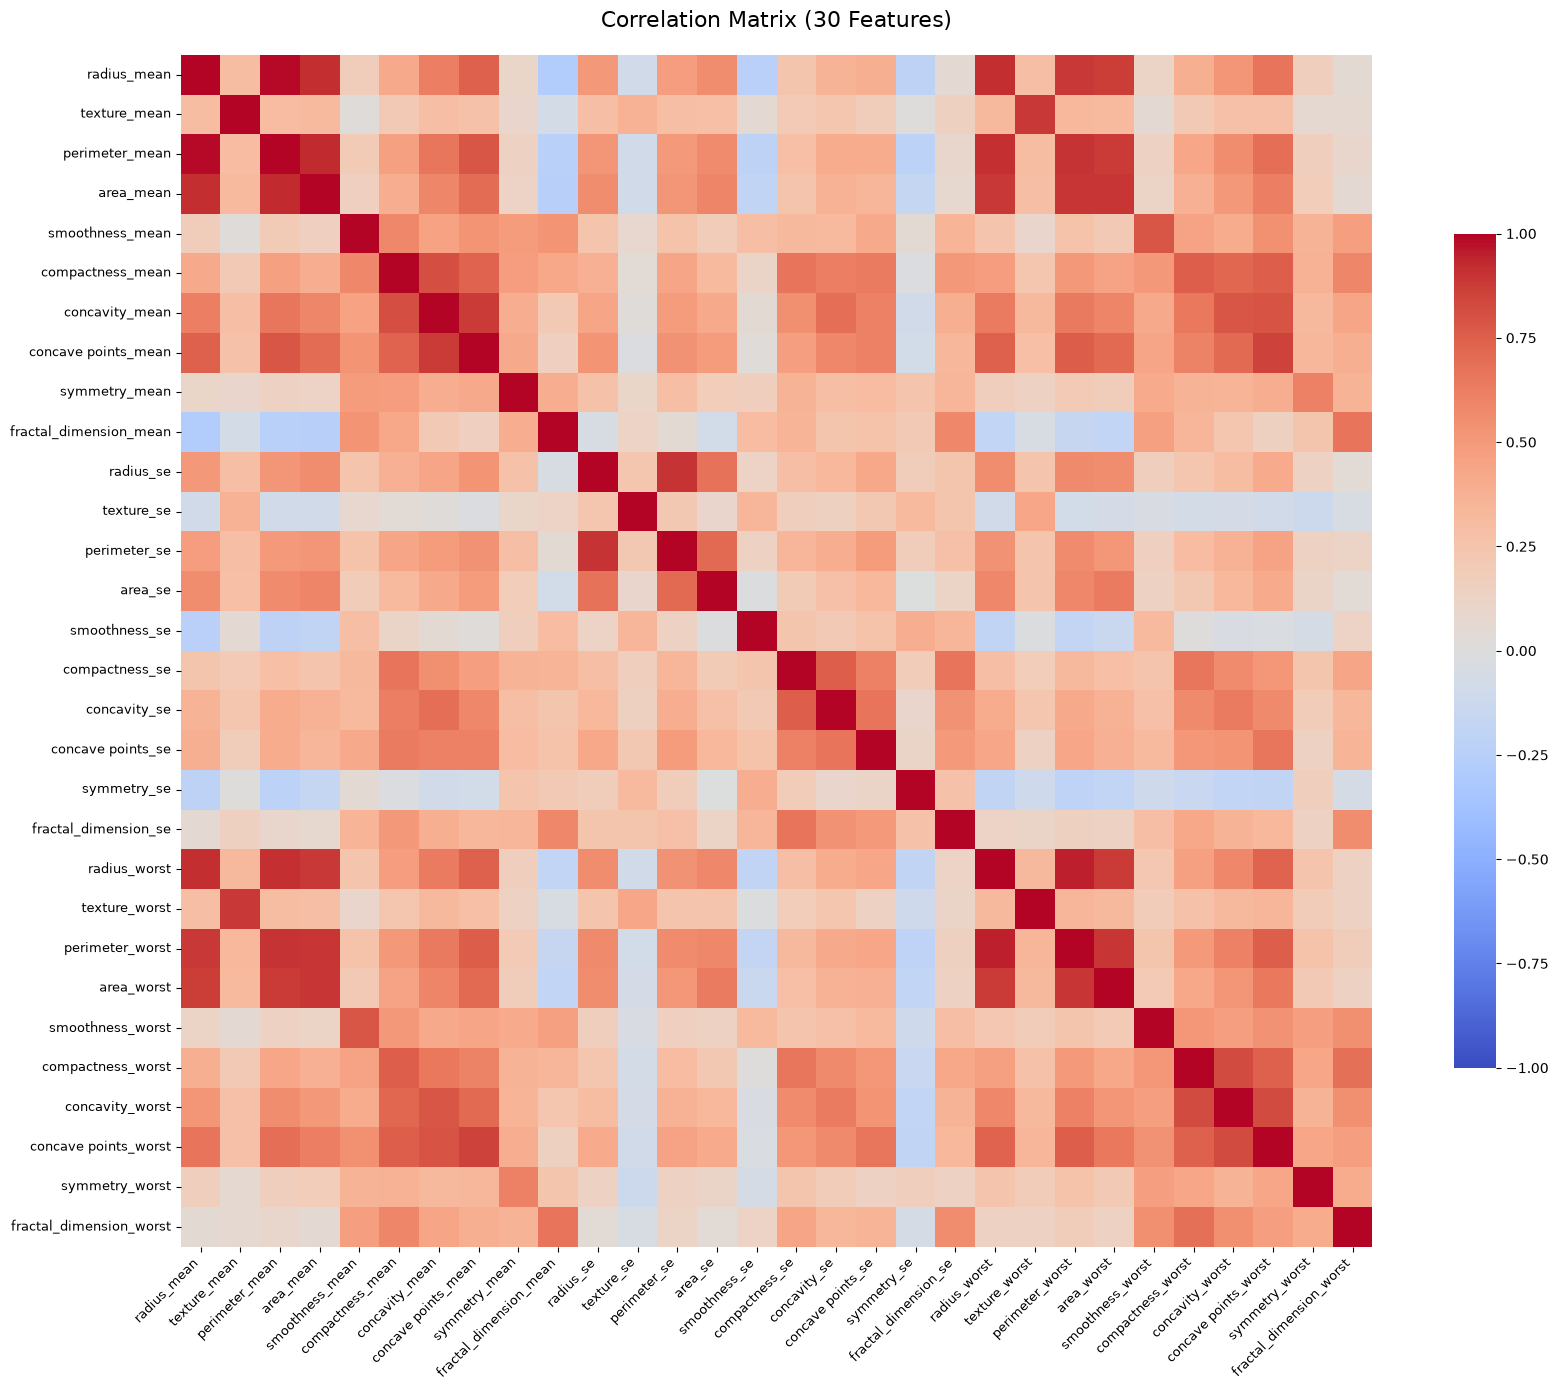

In [77]:
corr_matrix = X_train.corr()
plt.figure(figsize=(18, 14))


sns.heatmap(
    corr_matrix,
    annot=False,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    square=True,
    cbar_kws={"shrink": 0.7}
)

plt.xticks(fontsize=9, rotation=45, ha='right')
plt.yticks(fontsize=9, rotation=0)

plt.title('Correlation Matrix (30 Features)', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

In [78]:
corr_matrix = X_train.corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

corr_threshold = 0.9

to_drop = [
    col for col in upper.columns
    if any(upper[col] > corr_threshold)
]

X_train_reduced = X_train.drop(columns=to_drop)
X_test_reduced = X_test.drop(columns=to_drop)

print(f"Original features: {X_train.shape[1]}")
print(f"Remaining features: {X_train_reduced.shape[1]}")

X_train = X_train_reduced
X_test = X_test_reduced

Original features: 30
Remaining features: 25


In [79]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(y_pred[:10])

[-0.93776179  1.50591109 -0.5485295   0.06313395 -0.51187422 -0.19279379
  0.40246844 -0.88284103 -0.92386062 -0.71767381]


In [80]:
threshold = 0 # why did we keep the threshold as 0?

y_pred = np.where(y_pred > threshold, 1, -1)

Accuracy : 98.2%
Precision: 1.000
Recall   : 0.952
F1 Score   : 0.976


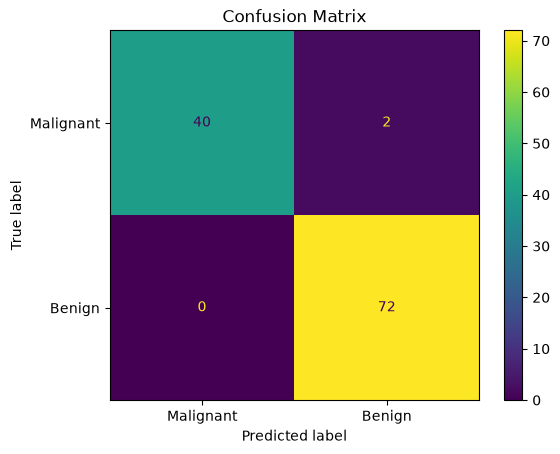

In [81]:
accuracy = np.mean(y_pred == y_test)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f'Accuracy : {accuracy*100:.1f}%')
print(f'Precision: {precision:.3f}')
print(f'Recall   : {recall:.3f}')
print(f'F1 Score   : {f1:.3f}')

cm = confusion_matrix(y_test, y_pred, labels = [1, -1]) # Calculate the confusion matrix
disp = ConfusionMatrixDisplay( # Initialize ConfusionMatrixDisplay with the calculated confusion matrix
    confusion_matrix=cm,
    display_labels = ['Malignant', 'Benign']
)

disp.plot() # Plot the confusion matrix

plt.title("Confusion Matrix") # Set the title of the plot
plt.show() # Display the plot